# Band structure and tight-binding models

The following notebook shows how to read and plot the DFT band structures. We also show how to read the tight-binding Hamiltonians and construct the bands to compare with DFT.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [11]:
def angles(N):
    """
    Return the angle corresponding to an integer N (see angles.txt)
    """
    return np.round(
        np.arccos(
            ((N - 1) ** 2 + 4 * N * (N - 1) + N ** 2) / (2 * ((N - 1) ** 2 + N * (N - 1) + N ** 2))
        ) * 180 / np.pi, 
        10
    )

## Reading and plotting the Siesta DFT band structures

The band structures of TBG are located in the files `bands-*.dat` in the `DFT-band-structures/` directory, with each file providing 50 bands below the charge neutrality point (CNP) and 50 bands above the CNP, giving 100 bands total. The band energies are given along the K-$\Gamma$-M-K path in the moir\'e Brillouin zone (mBZ). For angles between $21.87^\circ$ and $0.88^\circ$ (inclusive), there are 10 $k$-points along each path, giving 31 $k$-points total (with the $K$ point given twice). For angles smaller than $0.88^\circ$, fewer $k$-points are given due to computational cost. For those angles, see the comments in each band structure file for the $k$-points at which the band energies are given.

Below we read and plot the DFT band structure of TBG for twist angles between $0.93^\circ$ and $1.05^\circ$:

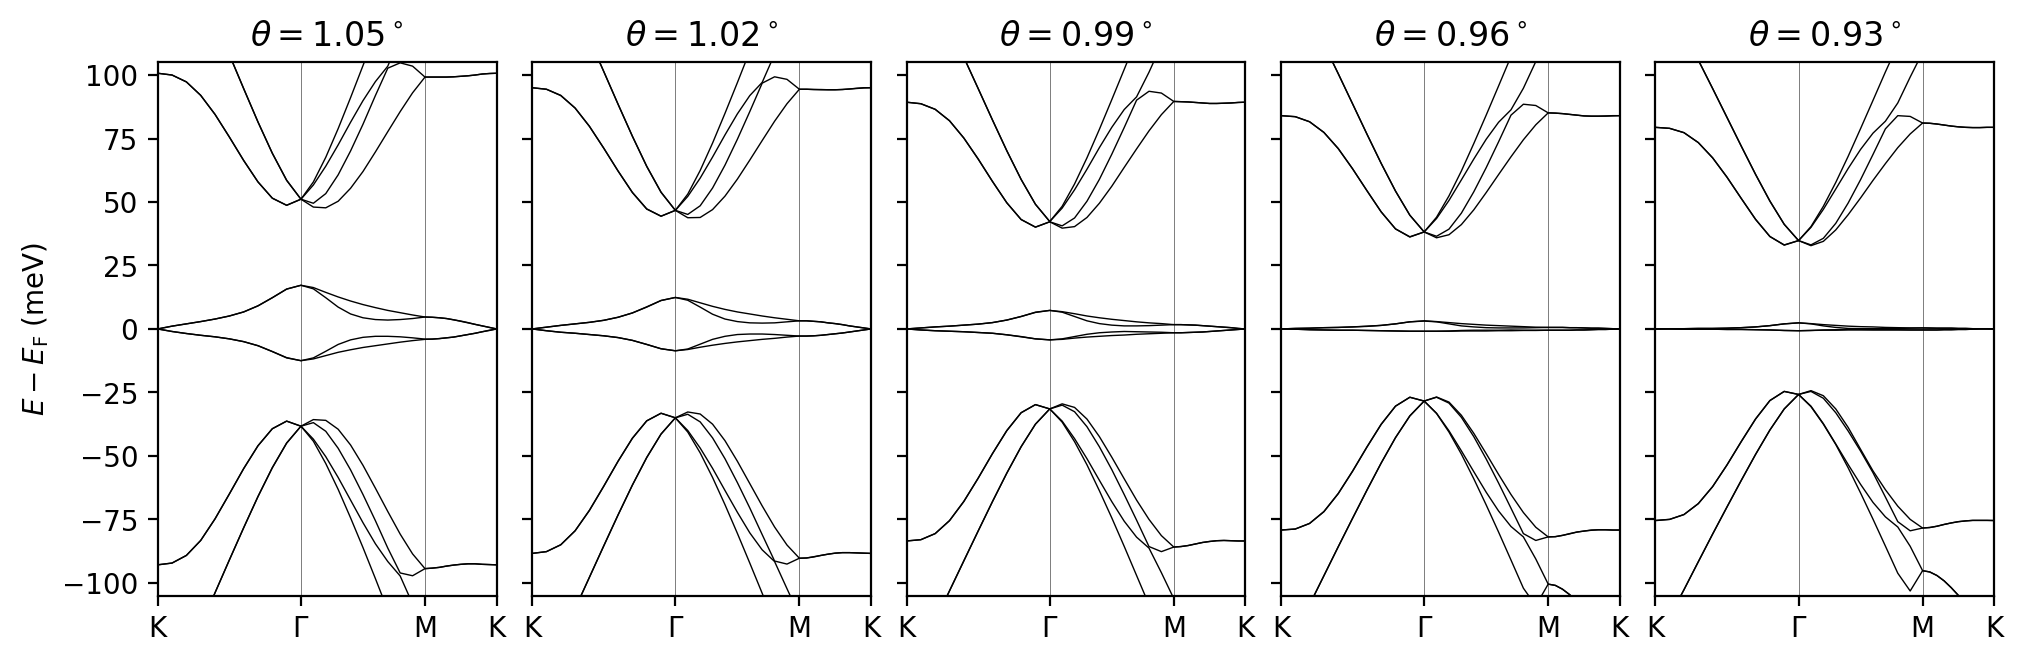

In [81]:
Ns = np.arange(32, 37, dtype=int)
fig, axs = plt.subplots(1, len(Ns), sharex=False, sharey=True, dpi=200, figsize=(2 * len(Ns), 3.2), layout="constrained")

Nkpoints = 31
for N, ax in zip(Ns, axs):

    # Load bands and separate k-points from band energies
    bands = np.loadtxt(f"DFT-band-structures/bands-{N}.dat")
    bands_k = bands[:Nkpoints, 0]
    bands_E = bands[:, 1].reshape((-1, Nkpoints)) * 1000     # Convert from eV to meV

    # The Siesta-calculated Fermi energy is often slightly offset from the CNP, so
    # we need to manually subtract the energy of the Dirac points from the bands
    flat_band_index = len(bands_E) // 2 - 2
    bands_E -= bands_E[flat_band_index, 0]   # Index 0 is the Dirac point

    # Plot bands for each angle
    for band in bands_E:
        ax.plot(bands_k, band, color='k', lw=0.5)
        ax.set_xlim(0, bands_k[-1])
        xticks = [0, bands_k[Nkpoints // 3], bands_k[2 * Nkpoints // 3], bands_k[-1]]
        xticks_labels = ["K", r"$\Gamma$", "M", "K"]
        ax.set_xticks(xticks, xticks_labels)
        ax.set_ylim(-105, 105)
        ax.axvline(bands_k[Nkpoints // 3], lw=0.3, color="grey", zorder=0)
        ax.axvline(bands_k[2 * Nkpoints // 3], lw=0.3, color="grey", zorder=0)
        ax.set_title(fr"$\theta = {angles(N):.2f}^\circ$")
axs[0].set_ylabel(r"$E - E_{\rm F}$ (meV)")
plt.show()

## Reading the tight-binding Hamiltonians

The tight-binding Hamiltonians are stored in the files `hamiltonian-*.dat` in the `tight-binding-hamiltonians/` directory. 

The Hamiltonians are written in `Wannier90` format:
- Line 1 is blank (usually reserved for a comment)
- Line 2 has a single integer denoting the number of basis orbitals (10)
- Line 3 has a single integer denoting the number of lattice vectors ${\bf R} = n{\bf a}_1 + m{\bf a}_2$ for which the Hamiltonian $H({\bf R})$ is defined ($n, m$ are integers, ${\bf a}_1, {\bf a}_2$ are the moir\'e lattice vectors). Note that $H_{ij}({\bf R})$ denotes the hopping from orbital $j$ in the unit cell translated by ${\bf R}$ to orbital $i$ in the original cell.
- Next there are a few lines with up to 15 columns per line that denote the degeneracy per lattice vector ${\bf R}$, a feature present in `Wannier90` to account for truncated ${\bf R}$. In our case, we have symmetrized and post-processed the tight-binding Hamiltonians such that all degeneracies are 1, so they will not be relevant for these Hamiltonians.
- The remaining lines have 7 columns each: column 1 stores $n$, column 2 stores $m$, column 3 is only applicable to 3D systems (so it is always 0 in our case), column 4 stores $i$, column 5 stores $j$, column 6 stores ${\rm Re}[H_{ij}(n{\bf a}_1 + m{\bf a}_2)]$, and column 7 stores ${\rm Im}[H_{ij}(n{\bf a}_1 + m{\bf a}_2)]$

The basis of each Hamiltonian is in the following order: $(\tau, p_z)$, $(\tau, p_+)_{\rm AA}$, $(\tau, p_-)_{\rm AA}$, $(\tau, s)$, $(\tau, p_+)_{\rm DW}$, $(\tau, p_-)_{\rm DW}$, $(\eta, p_+)_{\rm AB}$, $(\eta, p_-)_{\rm AB}$, $(\eta, p_+)_{\rm BA}$, $(\eta, p_-)_{\rm BA}$. By convention, within a single unit cell, the $\tau$ sites are located at fractional coordinates $(0, 0)$, and the AB and BA sites are located at fractional coordinates $(1/3, 1/3)$ and $(-1/3, -1/3)$, respectively.

Below we read the Hamiltonians for angles between $0.93^\circ$ and $1.05^\circ$ and store the lattice vectors ${\bf R}$ and hopping matrix elements $H_{ij}({\bf R})$ in a dictionary for each twist angle.

In [51]:
def read_hr(path):
    """
    Read a tight-binding Hamiltonian and return the lattice vectors R 
    and hopping matrix elements t
    """
    with open(path, "r", encoding="utf-8") as file:
        L = file.read().splitlines()
    
    # Number of basis orbital, number of lattice vectors
    nw, nr = int(L[1]), int(L[2])

    # Skip the degeneracy lines
    skip = 3 + -(-nr // 15)

    # Read and return the lattice vectors and hopping matrix elements
    R = np.zeros((nr, 3), int); t = np.zeros((nr, nw, nw), complex); seen = {}
    for line in L[skip:skip + nr * nw * nw]:
        f = line.split()
        key = (int(f[0]), int(f[1]), int(f[2]))  # Lattice vector
        i = seen.setdefault(key, len(seen))
        R[i] = key
        t[i, int(f[3]) - 1, int(f[4]) - 1] = float(f[5]) + 1j * float(f[6])  # Hopping
    
    return R, t

In [135]:
models = {}
Ns = np.arange(32, 37, dtype=int)
for N in Ns:
    R, t = read_hr(f"tight-binding-hamiltonians/hamiltonian-{N}.dat")
    models[N] = dict(R=R, t=t)

## Constructing bands

In the cells below, we show how to plot the band structure from the tight-binding models and compare them to the DFT band structures. The $k$-space Hamiltonian for each tight-binding model is given by
$$H_{ij}({\bf k}) = \sum_{\bf R} H_{ij}({\bf R}) e^{i{\bf k} \cdot {\bf R}}$$
$H({\bf k})$ is then diagonalized along the K-$\Gamma$-M-K path to plot a band structure and compare against the DFT bands.

In [49]:
pub[35]['t'][32]

array([[ 4.46113315e-03+0.j        , -2.86871652e-03-0.00165625j,
         2.61939560e-03-0.00151231j,  0.00000000e+00-0.00191788j,
        -6.58246626e-03-0.00380039j,  1.73453170e-03-0.00100143j,
         1.61995795e-04-0.00026885j, -8.08175956e-04-0.00037992j,
        -5.29143188e-03+0.02029923j, -2.02253651e-02+0.0055671j ],
       [ 2.61939560e-03-0.00151231j, -2.01346694e-03+0.j        ,
         1.30705253e-03-0.00226388j, -6.21896593e-04-0.00107716j,
        -4.94786427e-03+0.j        ,  5.42631095e-04-0.00093986j,
         4.34494322e-04+0.00065124j, -9.07508550e-05+0.00015155j,
         4.47185306e-03+0.00170579j, -1.00074945e-02+0.02015751j],
       [-2.86871652e-03-0.00165625j,  1.12588155e-03+0.00195008j,
        -2.01346694e-03+0.j        , -1.99673239e-04+0.00034584j,
         1.91883546e-03+0.00332352j, -2.04079172e-03+0.j        ,
        -4.10625070e-05+0.00045043j,  8.54962213e-04+0.00100593j,
         2.24606631e-02-0.00141201j,  4.47185306e-03+0.00170579j],
       

In [129]:
def bands(R, t, k):
    """
    Constructs H(k) from the real-space Hamiltonian and diagonalizes to obtain the band energies
    """
    H = np.einsum("kr,rmn->kmn", np.exp(2j * np.pi * (k @ np.asarray(R)[:, :2].T)), t)
    return np.linalg.eigvalsh(0.5 * (H + H.conj().transpose(0, 2, 1)))

# Number of k-points along each path
Nk_model = 101
K, G, M = np.array([2 / 3, 1 / 3]), np.array([0.0, 0.0]), np.array([0.5, 0.0])
k_path = np.vstack(
    [
        np.linspace(K, G, Nk_model), 
        np.linspace(G, M, Nk_model)[1:], 
        np.linspace(M, K, Nk_model)[1:]
    ]
)
k_prime_path = -np.vstack(
    [
        np.linspace(K, G, Nk_model), 
        np.linspace(G, M, Nk_model)[1:], 
        np.linspace(M, K, Nk_model)[1:]
    ]
)

# Distance along the k-path
model_k_dists = np.concatenate(
    (
        np.linspace(0, np.linalg.norm(K), Nk_model),
        np.linspace(np.linalg.norm(K), (1 + np.sqrt(3) / 2) * np.linalg.norm(K), Nk_model)[1:],
        np.linspace((1 + np.sqrt(3) / 2) * np.linalg.norm(K), (1.5 + np.sqrt(3) / 2) * np.linalg.norm(K), Nk_model)[1:]
    )
)

model_k_bands = {}
model_k_prime_bands = {}
for N in Ns:
    model_k_bands[N] = bands(models[N]["R"], models[N]["t"], k_path)
    model_k_bands[N] = (model_k_bands[N] - model_k_bands[N][0, 4])
    model_k_prime_bands[N] = bands(models[N]["R"], models[N]["t"], k_prime_path)
    model_k_prime_bands[N] = (model_k_prime_bands[N] - model_k_prime_bands[N][0, 4])

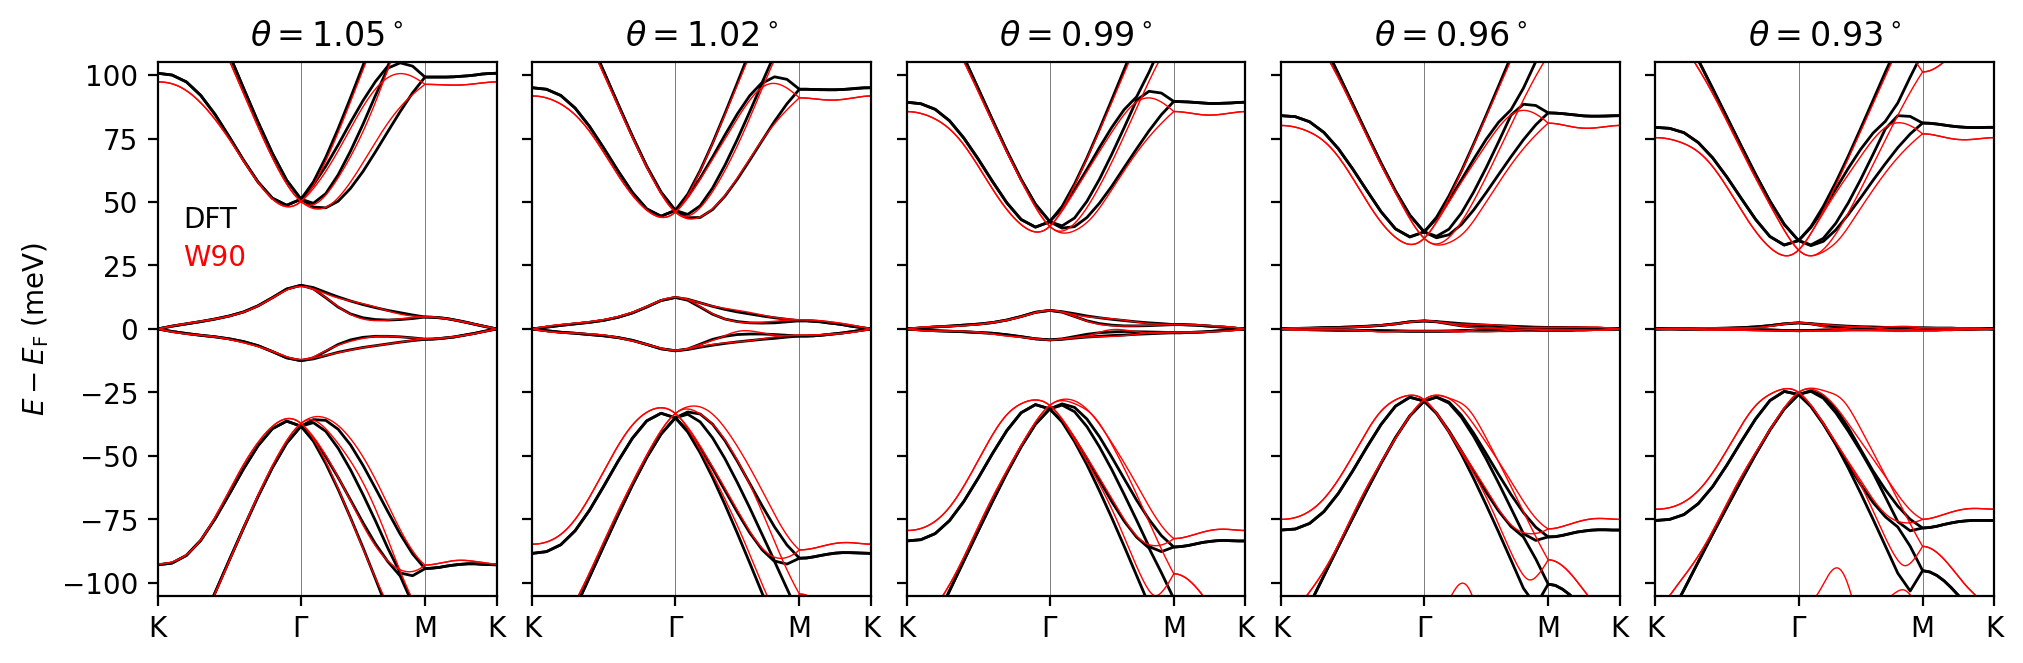

In [130]:
fig, axs = plt.subplots(1, len(Ns), sharex=False, sharey=True, dpi=200, figsize=(2 * len(Ns), 3.2), layout="constrained")

Nkpoints = 31
for N, ax in zip(Ns, axs):

    # Load bands and separate k-points from band energies
    bands = np.loadtxt(f"DFT-band-structures/bands-{N}.dat")
    bands_k = bands[:Nkpoints, 0]
    bands_E = bands[:, 1].reshape((-1, Nkpoints)) * 1000     # Convert from eV to meV

    # The Siesta-calculated Fermi energy is often slightly offset from the CNP, so
    # we need to manually subtract the energy of the Dirac points from the bands
    flat_band_index = len(bands_E) // 2 - 2
    bands_E -= bands_E[flat_band_index, 0]   # Index 0 is the Dirac point

    # Tight-binding Hamiltonian bands
    model_k_E = model_k_bands[N].T * 1000
    model_k_prime_E = model_k_prime_bands[N].T * 1000
    model_k_dists *= bands_k[-1] / model_k_dists[-1]
    
    # Plot DFT bands for each angle
    for band in bands_E:
        ax.plot(bands_k, band, color='k', lw=1)
        ax.set_xlim(0, bands_k[-1])
        xticks = [0, bands_k[Nkpoints // 3], bands_k[2 * Nkpoints // 3], bands_k[-1]]
        xticks_labels = ["K", r"$\Gamma$", "M", "K"]
        ax.set_xticks(xticks, xticks_labels)
        ax.set_ylim(-105, 105)
        ax.axvline(bands_k[Nkpoints // 3], lw=0.3, color="grey", zorder=0)
        ax.axvline(bands_k[2 * Nkpoints // 3], lw=0.3, color="grey", zorder=0)
        ax.set_title(fr"$\theta = {angles(N):.2f}^\circ$")

    # Plot tight-binding Hamiltonian bands for each angle
    for band_k, band_k_prime in zip(model_k_E, model_k_prime_E):
        ax.plot(model_k_dists, band_k, color='r', lw=0.5)
        ax.plot(model_k_dists, band_k_prime, color='r', lw=0.5)
    
axs[0].set_ylabel(r"$E - E_{\rm F}$ (meV)")
axs[0].text(bands_k[Nkpoints // 15], 40, "DFT", color="k")
axs[0].text(bands_k[Nkpoints // 15], 25, "W90", color="r")

plt.show()